# 01 - Brain MRI Multimodal Data Exploration



1. **Inventory & Structure Verification**: Inspect the raw dataset in `data/raw/{Train|Val}/{ClassName}/{images|labels}`.
2. **Class Distribution Analysis**: Profile the 4 brain MRI categories (`Glioma`, `Meningioma`, `No Tumor`, `Pituitary`).
3. **Data Integrity & Resolution Profiling**: Check for corrupted images, inspect dimensions (widths, heights, aspect ratios).
4. **Visual Inspection**: Display representative MRI scans across all pathological classes.
5. **YOLO Annotation Audit**: Validate bounding boxes (`class_id cx cy w h` in $[0, 1]$) and visualize lesion overlays.
6. **Report Export**: Save structured metrics to `outputs/reports/exploration_report.json` for full traceability.

## [1] Setup & Environment Configuration

In [2]:
import json
import os
from pathlib import Path

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

# Determine project root path portably
HERE = Path.cwd()
ROOT = HERE.parent if HERE.name == "notebooks" else HERE

DATA_DIR = ROOT / "data" / "raw"
REPORT_DIR = ROOT / "outputs" / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]
VALID_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}

# print("Project root :", ROOT.resolve())
# print("Data folder  :", DATA_DIR.resolve())
# print("Report folder:", REPORT_DIR.resolve())
print("Raw data exists:", DATA_DIR.exists())

Raw data exists: True


## [2] Dataset Inventory & Class Distribution

In [3]:
# Scan all images and labels across Train and Val splits
records = []

for split in ["Train", "Val"]:
    split_dir = DATA_DIR / split
    if not split_dir.exists():
        continue

    for class_folder in sorted(split_dir.iterdir()):
        if not class_folder.is_dir():
            continue

        class_name = class_folder.name
        images_dir = class_folder / "images"
        labels_dir = class_folder / "labels"

        images = list(images_dir.glob("*")) if images_dir.exists() else []
        labels = list(labels_dir.glob("*.txt")) if labels_dir.exists() else []

        for img_p in images:
            if img_p.suffix.lower() in VALID_EXTS:
                lbl_p = labels_dir / (img_p.stem + ".txt")
                records.append({
                    "split": split,
                    "class": class_name,
                    "filename": img_p.name,
                    "stem": img_p.stem,
                    "image_path": str(img_p),
                    "label_path": str(lbl_p) if lbl_p.exists() else None,
                    "has_label": lbl_p.exists()
                })

df_dataset = pd.DataFrame(records)
print(f"Total images cataloged: {len(df_dataset)}")

# Tabular breakdown
summary_table = pd.crosstab(df_dataset["class"], df_dataset["split"], margins=True, margins_name="Total")
print("\n--- Class Breakdown across Raw Splits ---")
display(summary_table) if "display" in globals() else print(summary_table)

Total images cataloged: 5249

--- Class Breakdown across Raw Splits ---
split       Train  Val  Total
class                        
Glioma       1153  136   1289
Meningioma   1449  140   1589
No Tumor      711  100    811
Pituitary    1424  136   1560
Total        4737  512   5249


### Class Distribution Visualization

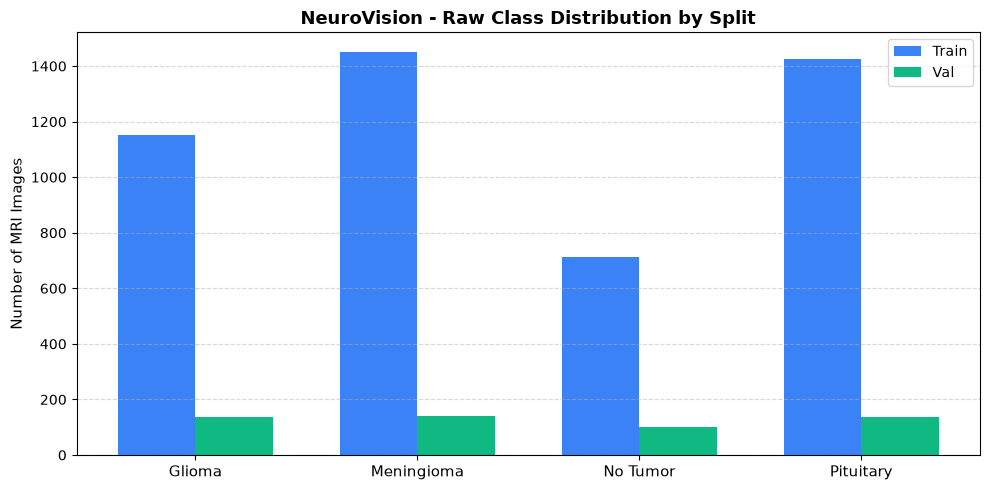

In [4]:
# Plot comparative bar chart of class counts
plt.figure(figsize=(10, 5))

pivot_counts = pd.crosstab(df_dataset["class"], df_dataset["split"])
x = np.arange(len(pivot_counts))
width = 0.35

plt.bar(x - width/2, pivot_counts["Train"], width, label="Train", color="#3B82F6")
plt.bar(x + width/2, pivot_counts["Val"], width, label="Val", color="#10B981")

plt.xticks(x, pivot_counts.index, fontsize=11)
plt.ylabel("Number of MRI Images", fontsize=11)
plt.title("NeuroVision - Raw Class Distribution by Split", fontsize=13, fontweight="bold")
plt.legend(frameon=True)
plt.grid(axis="y", linestyle="--", alpha=0.5)

chart_path = REPORT_DIR / "raw_class_distribution.png"
plt.tight_layout()
plt.savefig(chart_path, dpi=120)
plt.show()
# print(f"Saved distribution chart to: {chart_path}")

## [3] Image Integrity & Resolution Profiling

We verify that every image can be decoded and collect width, height, aspect ratio, and channel information.

In [5]:
corrupted_files = []
widths = []
heights = []
aspect_ratios = []
modes = []
file_sizes_kb = []

print("Verifying image integrity across dataset...")
for idx, row in df_dataset.iterrows():
    p = Path(row["image_path"])
    try:
        with Image.open(p) as img:
            img.verify()  # Check for corruption
        
        # Re-open to read dimensions
        with Image.open(p) as img:
            w, h = img.size
            widths.append(w)
            heights.append(h)
            aspect_ratios.append(round(w / h, 3))
            modes.append(img.mode)
            file_sizes_kb.append(round(p.stat().st_size / 1024, 1))
    except Exception as e:
        corrupted_files.append({"path": str(p), "error": str(e)})
        widths.append(None)
        heights.append(None)
        aspect_ratios.append(None)
        modes.append(None)
        file_sizes_kb.append(None)

df_dataset["width"] = widths
df_dataset["height"] = heights
df_dataset["aspect_ratio"] = aspect_ratios
df_dataset["mode"] = modes
df_dataset["size_kb"] = file_sizes_kb

print(f"\nCorrupted images found: {len(corrupted_files)}")
if corrupted_files:
    for c in corrupted_files[:5]:
        print("  Corrupted:", c)
else:
    print("All images successfully verified and read without corruption!")

# Statistical summary of dimensions
print("\n--- Image Dimensions Summary ---")
dim_summary = df_dataset[["width", "height", "aspect_ratio", "size_kb"]].describe().round(2)
display(dim_summary) if "display" in globals() else print(dim_summary)

Verifying image integrity across dataset...

Corrupted images found: 0
All images successfully verified and read without corruption!

--- Image Dimensions Summary ---
         width   height  aspect_ratio  size_kb
count  5249.00  5249.00       5249.00  5249.00
mean    481.95   484.47          0.99    26.05
std     106.06   100.13          0.07    14.96
min     150.00   168.00          0.64     3.60
25%     512.00   512.00          1.00    19.50
50%     512.00   512.00          1.00    25.00
75%     512.00   512.00          1.00    30.40
max    1375.00  1446.00          1.79   299.30


### Resolution Distribution Plot

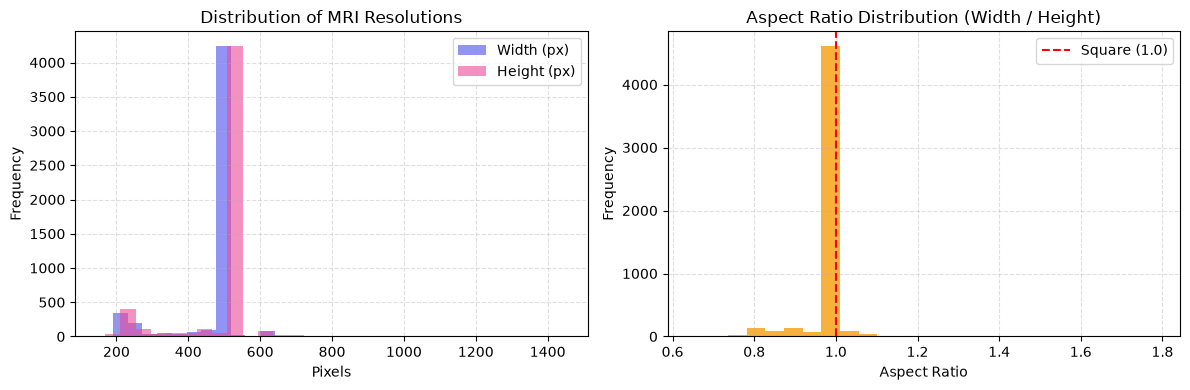

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Width and Height histograms
axes[0].hist(df_dataset["width"].dropna(), bins=30, color="#6366F1", alpha=0.7, label="Width (px)")
axes[0].hist(df_dataset["height"].dropna(), bins=30, color="#EC4899", alpha=0.6, label="Height (px)")
axes[0].set_title("Distribution of MRI Resolutions", fontsize=12)
axes[0].set_xlabel("Pixels")
axes[0].set_ylabel("Frequency")
axes[0].legend()
axes[0].grid(linestyle="--", alpha=0.4)

# Aspect ratio distribution
axes[1].hist(df_dataset["aspect_ratio"].dropna(), bins=25, color="#F59E0B", alpha=0.8)
axes[1].axvline(1.0, color="red", linestyle="--", label="Square (1.0)")
axes[1].set_title("Aspect Ratio Distribution (Width / Height)", fontsize=12)
axes[1].set_xlabel("Aspect Ratio")
axes[1].set_ylabel("Frequency")
axes[1].legend()
axes[1].grid(linestyle="--", alpha=0.4)

plt.tight_layout()
res_chart_path = REPORT_DIR / "image_resolutions.png"
plt.savefig(res_chart_path, dpi=120)
plt.show()
# print(f"Saved resolution plots to: {res_chart_path}")

## [4] Multi-Class MRI Visual Gallery

We display representative axial brain MRI slices from each of the 4 classes to visually inspect image contrast, lesion appearance, and normalization.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


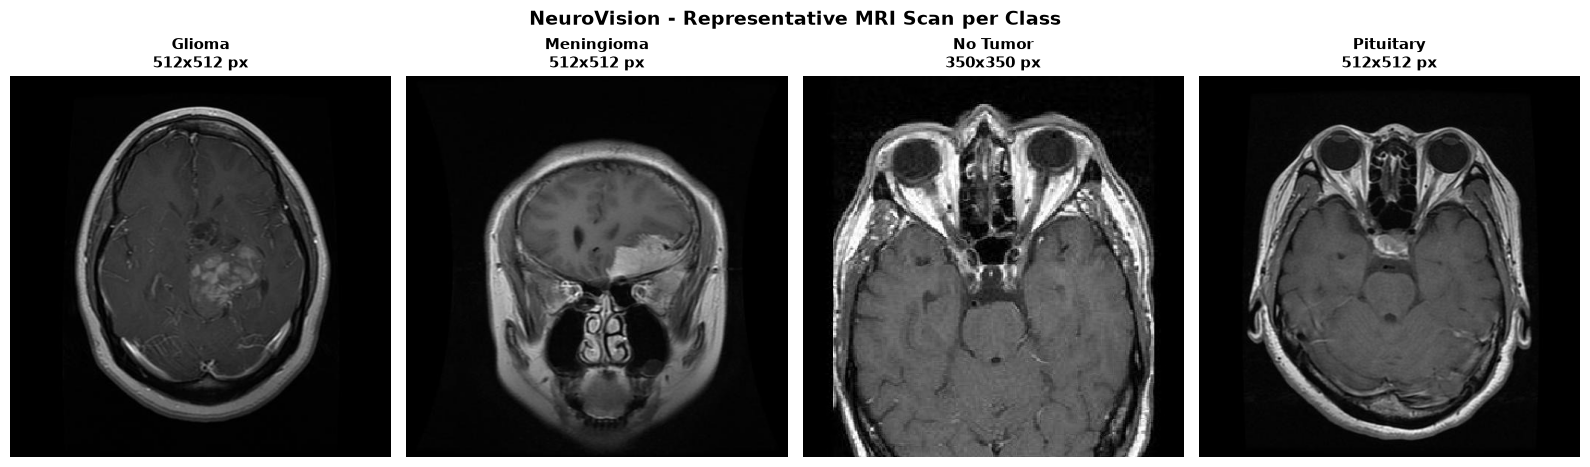

In [7]:
fig, axes = plt.subplots(1, len(CLASSES), figsize=(4 * len(CLASSES), 4.5))

for ax, cls in zip(axes, CLASSES):
    sample_rows = df_dataset[df_dataset["class"] == cls]
    if not sample_rows.empty:
        sample = sample_rows.iloc[0]
        img = Image.open(sample["image_path"]).convert("RGB")
        ax.imshow(img)
        ax.set_title(f"{cls}\n{sample['width']}x{sample['height']} px", fontsize=11, fontweight="semibold")
    ax.axis("off")

plt.suptitle("NeuroVision - Representative MRI Scan per Class", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
gallery_path = REPORT_DIR / "mri_class_samples.png"
plt.savefig(gallery_path, dpi=120, bbox_inches="tight")
plt.show()
# print(f"Saved MRI gallery to: {gallery_path}")

## [5] YOLO Bounding Box Annotations Audit

Detection models (YOLOv8) require normalized annotations formatted as:
`<class_id> <cx> <cy> <w> <h>` where coordinates are in $[0, 1]$.

In this dataset, **`class_id = 0` denotes a tumor** lesion.

In [8]:
matched_pairs = 0
missing_labels = 0
empty_labels = 0
invalid_boxes = []
sample_boxes_to_draw = []

for idx, row in df_dataset.iterrows():
    if not row["has_label"]:
        missing_labels += 1
        continue

    lbl_p = Path(row["label_path"])
    matched_pairs += 1
    content = lbl_p.read_text(encoding="utf-8", errors="ignore").strip()

    if not content:
        empty_labels += 1
        continue

    # Validate format
    for line_idx, line in enumerate(content.splitlines(), 1):
        parts = line.strip().split()
        if len(parts) != 5:
            invalid_boxes.append({"file": lbl_p.name, "line": line_idx, "reason": f"Expected 5 values, got {len(parts)}"})
            continue

        try:
            cid = int(parts[0])
            cx, cy, bw, bh = map(float, parts[1:])
        except ValueError:
            invalid_boxes.append({"file": lbl_p.name, "line": line_idx, "reason": "Non-numeric coordinate"})
            continue

        if not (0 <= cx <= 1 and 0 <= cy <= 1 and 0 < bw <= 1 and 0 < bh <= 1):
            invalid_boxes.append({"file": lbl_p.name, "line": line_idx, "reason": f"Out of bounds: {[cx, cy, bw, bh]}"})

    # Keep up to 4 samples for overlay visualization
    if len(sample_boxes_to_draw) < 4 and content and row["class"] != "No Tumor":
        sample_boxes_to_draw.append(row)

print(f"Matched Image-Label pairs : {matched_pairs}")
print(f"Images with Missing Label : {missing_labels}")
print(f"Empty Label files (Neg)   : {empty_labels}")
print(f"Invalid Bounding Boxes    : {len(invalid_boxes)}")

Matched Image-Label pairs : 5247
Images with Missing Label : 2
Empty Label files (Neg)   : 1
Invalid Bounding Boxes    : 0


### Ground Truth Bounding Box Visual Overlay

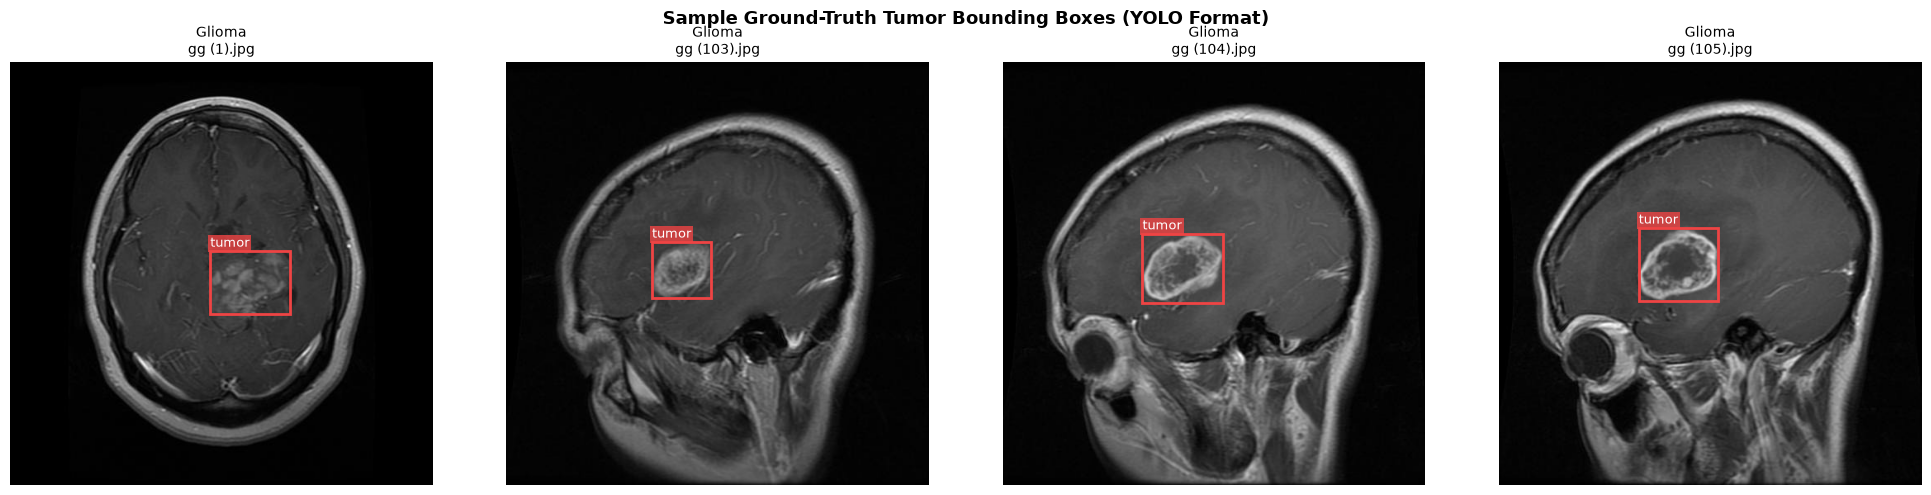

In [9]:
# Render ground-truth bounding boxes on sample MRI scans
if sample_boxes_to_draw:
    fig, axes = plt.subplots(1, len(sample_boxes_to_draw), figsize=(5 * len(sample_boxes_to_draw), 5))
    if len(sample_boxes_to_draw) == 1:
        axes = [axes]

    for ax, row in zip(axes, sample_boxes_to_draw):
        img = Image.open(row["image_path"]).convert("RGB")
        w_img, h_img = img.size
        ax.imshow(img)

        content = Path(row["label_path"]).read_text(encoding="utf-8").strip()
        for line in content.splitlines():
            parts = line.strip().split()
            if len(parts) == 5:
                cx, cy, bw, bh = map(float, parts[1:])
                x1 = (cx - bw / 2) * w_img
                y1 = (cy - bh / 2) * h_img
                box_w = bw * w_img
                box_h = bh * h_img
                rect = patches.Rectangle((x1, y1), box_w, box_h, linewidth=2, edgecolor="#EF4444", facecolor="none")
                ax.add_patch(rect)
                ax.text(x1, max(y1 - 5, 10), "tumor", color="white", fontsize=9, bbox=dict(facecolor="#EF4444", alpha=0.8, edgecolor="none", pad=1.5))

        ax.set_title(f"{row['class']}\n{row['filename']}", fontsize=10)
        ax.axis("off")

    plt.suptitle("Sample Ground-Truth Tumor Bounding Boxes (YOLO Format)", fontsize=13, fontweight="bold")
    plt.tight_layout()
    boxes_plot_path = REPORT_DIR / "yolo_sample_annotations.png"
    plt.savefig(boxes_plot_path, dpi=120)
    plt.show()
    # print(f"Saved annotated bounding boxes visualization to: {boxes_plot_path}")

## [6] Key Findings & Exporting Data Exploration Report

In [10]:
# Export structured exploration report as JSON
class_counts_dict = df_dataset["class"].value_counts().to_dict()

report = {
    "project": "NeuroVision",
    "phase": "01_data_exploration",
    "total_images": int(len(df_dataset)),
    "total_valid": int(len(df_dataset) - len(corrupted_files)),
    "total_corrupted": int(len(corrupted_files)),
    "classes": sorted(list(df_dataset["class"].unique())),
    "class_counts": class_counts_dict,
    "splits": {
        "Train": int((df_dataset["split"] == "Train").sum()),
        "Val": int((df_dataset["split"] == "Val").sum())
    },
    "yolo_matched_pairs": matched_pairs,
    "yolo_missing_labels": missing_labels,
    "yolo_empty_labels": empty_labels,
    "dimensions": {
        "width_min": int(df_dataset["width"].min()),
        "width_max": int(df_dataset["width"].max()),
        "width_mean": float(round(df_dataset["width"].mean(), 1)),
        "height_min": int(df_dataset["height"].min()),
        "height_max": int(df_dataset["height"].max()),
        "height_mean": float(round(df_dataset["height"].mean(), 1))
    },
    "plots": [
        str(chart_path.name),
        str(res_chart_path.name),
        str(gallery_path.name)
    ]
}

report_json_path = REPORT_DIR / "exploration_report.json"
with open(report_json_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

# print(f"Report successfully exported to: {report_json_path}")

# Print Medical AI Synthesis
print("\n" + "="*60)
print("NeuroVision Data Exploration Summary:")
print("="*60)
print(f"[] Total Verified Images : {report['total_valid']}")
print(f"[] Number of Classes     : {len(report['classes'])} -> {report['classes']}")
print(f"[] Dimensions Range      : [{report['dimensions']['width_min']}x{report['dimensions']['height_min']}] to [{report['dimensions']['width_max']}x{report['dimensions']['height_max']}]")
print(f"[] YOLO Matched Pairs    : {report['yolo_matched_pairs']} pairs ready for detection")

print("="*60)


NeuroVision Data Exploration Summary:
[] Total Verified Images : 5249
[] Number of Classes     : 4 -> ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']
[] Dimensions Range      : [150x168] to [1375x1446]
[] YOLO Matched Pairs    : 5247 pairs ready for detection
